In [44]:
import pandas as pd

df = pd.read_csv("../data/raw/data.csv")
df.head()

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,40.900749,95.40,0.00,95.4,0.000000,1000.0,201.802084
1,C10002,3202.467416,0.00,0.00,0.0,6442.945483,7000.0,4103.032597
2,C10003,2495.148862,773.17,773.17,0.0,0.000000,7500.0,622.066742
3,C10004,1666.670542,1499.00,1499.00,0.0,205.788017,7500.0,0.000000
4,C10005,817.714335,16.00,16.00,0.0,0.000000,1200.0,678.334763


In [45]:
df.columns
df.dtypes
df.shape
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CUST_ID                 8950 non-null   str    
 1   BALANCE                 8950 non-null   float64
 2   PURCHASES               8950 non-null   float64
 3   ONEOFF_PURCHASES        8950 non-null   float64
 4   INSTALLMENTS_PURCHASES  8950 non-null   float64
 5   CASH_ADVANCE            8950 non-null   float64
 6   CREDIT_LIMIT            8949 non-null   float64
 7   PAYMENTS                8950 non-null   float64
dtypes: float64(7), str(1)
memory usage: 559.5 KB


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000
mean,1564.474828,1003.204834,592.437371,411.067645,978.871112,4494.449450,1733.143852
std,2081.531879,2136.634782,1659.887917,904.338115,2097.163877,3638.815725,2895.063757
min,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000
25%,128.281915,39.635000,0.000000,0.000000,0.000000,1600.000000,383.276166
50%,873.385231,361.280000,38.000000,89.000000,0.000000,3000.000000,856.901546
75%,2054.140036,1110.130000,577.405000,468.637500,1113.821139,6500.000000,1901.134317
max,19043.138560,49039.570000,40761.250000,22500.000000,47137.211760,30000.000000,50721.483360


In [46]:
df.duplicated().sum()
df.isna().sum
df[df["CREDIT_LIMIT"].isna()]
df = df.dropna(subset=["CREDIT_LIMIT"])
df[df["CREDIT_LIMIT"].isna()]
df

,CUST_ID,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS
0,C10001,40.900749,95.40,0.00,95.40,0.000000,1000.0,201.802084
1,C10002,3202.467416,0.00,0.00,0.00,6442.945483,7000.0,4103.032597
2,C10003,2495.148862,773.17,773.17,0.00,0.000000,7500.0,622.066742
3,C10004,1666.670542,1499.00,1499.00,0.00,205.788017,7500.0,0.000000
4,C10005,817.714335,16.00,16.00,0.00,0.000000,1200.0,678.334763
...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,291.12,0.00,291.12,0.000000,1000.0,325.594462
8946,C19187,19.183215,300.00,0.00,300.00,0.000000,1000.0,275.861322
8947,C19188,23.398673,144.40,0.00,144.40,0.000000,1000.0,81.270775
8948,C19189,13.457564,0.00,0.00,0.00,36.558778,500.0,52.549959


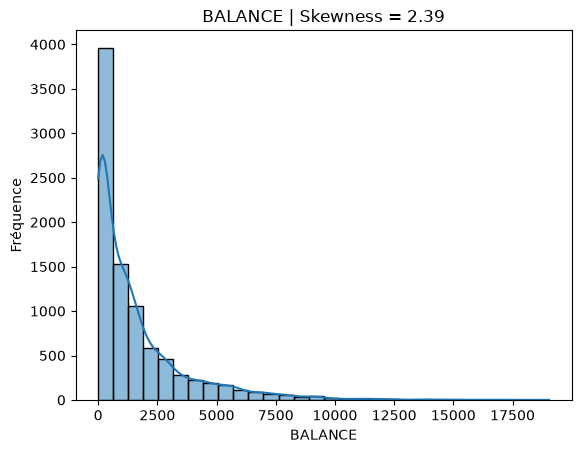

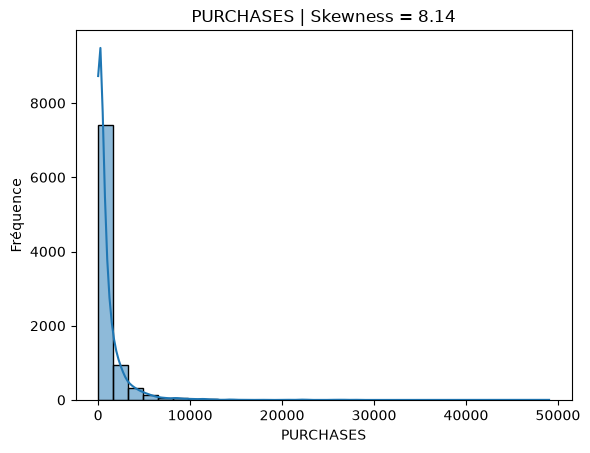

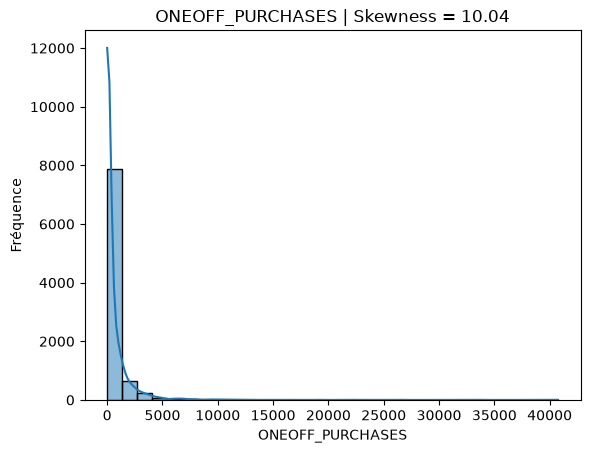

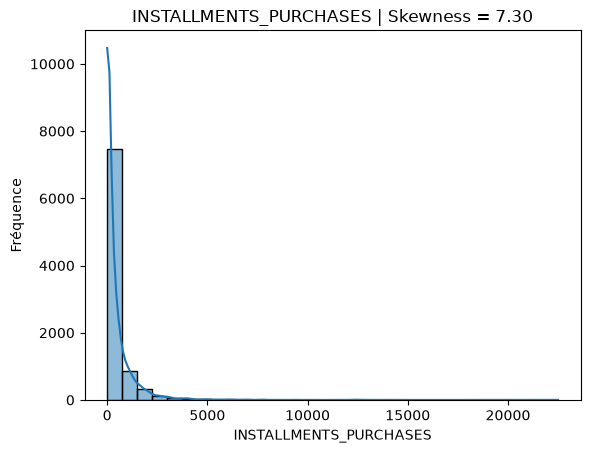

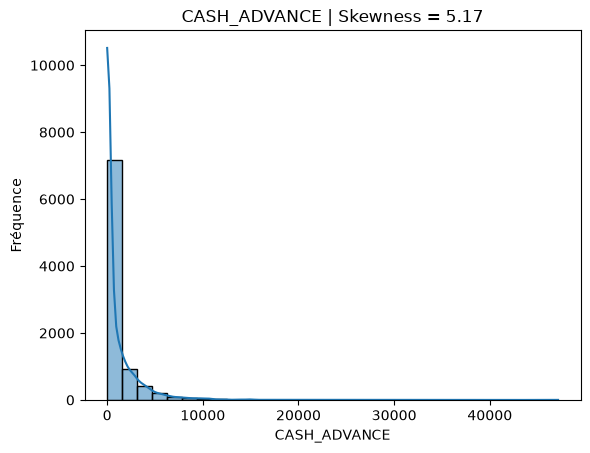

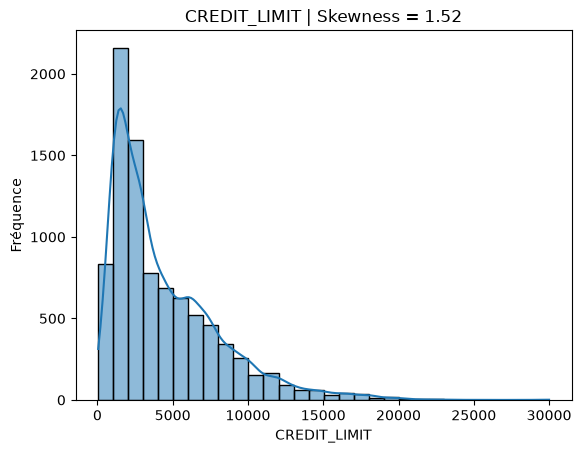

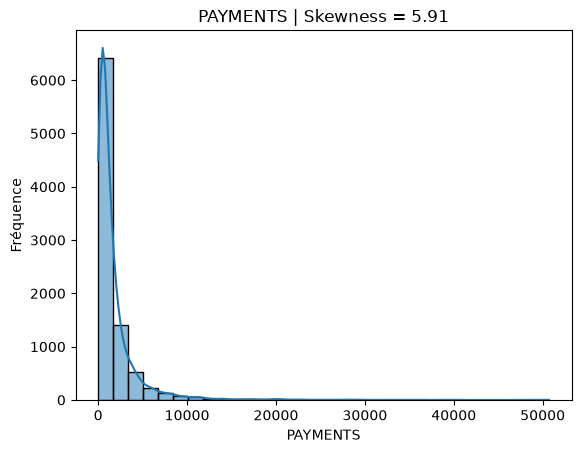

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in num_cols:
    skew = df[col].skew()
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"{col} | Skewness = {skew:.2f}")
    plt.xlabel(col)
    plt.ylabel("Fréquence")
    plt.show()

In [48]:
skewness = df[num_cols].skew()
print("Variables fortement asymetriques :")
print(skewness[skewness.abs() > 1])

Variables fortement asymetriques :
BALANCE                    2.393270
PURCHASES                  8.143969
ONEOFF_PURCHASES          10.044622
INSTALLMENTS_PURCHASES     7.298823
CASH_ADVANCE               5.166323
CREDIT_LIMIT               1.522464
PAYMENTS                   5.907465
dtype: float64


In [49]:
corr_matrix = num_cols.corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

AttributeError: 'Index' object has no attribute 'corr'

In [ ]:
for col in num_cols:
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot de {col}")
    plt.xlabel(col)
    plt.show()

In [ ]:
outliers_in_all = []
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) |(df[col] > upper)]

    outliers_in_all.append({"Variable": col,
        "Nombre d'outliers": len(outliers),
        "Pourcentage": round(len(outliers) / len(df) * 100, 2)
    })
outliers_df = pd.DataFrame(outliers_in_all)
outliers_df

In [ ]:
sns.barplot(
    data=outliers_df,
    x="Variable",
    y="Nombre d'outliers"
)
plt.xticks(rotation=50, ha="right")
plt.title("Nombre d'outliers par variabl")
plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
colonnes_inutiles = ["CUST_ID"]
df_clean = df_clean.drop(columns=colonnes_inutiles)
df_clean.to_csv("df_clean.csv",index=False)

In [ ]:
df_clean.columns

Index(['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES',
       'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS'],
      dtype='str')

In [ ]:
df_prepare_clustering = df_clean.copy()
features = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
for col in features:
    if (df_prepare_clustering[col] < 0).any():
        print(f"{col} contains zero or negative values")

BALANCE is positive
PURCHASES is positive
ONEOFF_PURCHASES is positive
INSTALLMENTS_PURCHASES is positive
CASH_ADVANCE is positive
CREDIT_LIMIT is positive
PAYMENTS is positive
